In [1]:
import os 
import numpy as np 
import pandas as pd 
# import scipy.stats as stats
# from scipy.stats import pearsonr 
import matplotlib.pyplot as plt 
# import seaborn as sns 
import tarfile
import tqdm

/tmp/ipykernel_411073/1888587986.py:3: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


In [ ]:
# Load demo count data (raw count)
basic_dir = "/lustre/nvwulf/home/ronsharma/breaststuff"
X = pd.read_csv(os.path.join(basic_dir, "X.csv"), index_col=0)
X.index.name = "patient_id"
yiv = pd.read_csv(os.path.join(basic_dir, "yiv.csv"))

: 

In [3]:
print(yiv.value_counts())
print(yiv.shape)
print(X.shape)

0  
0.0    1032
1.0      19
Name: count, dtype: int64
(1051, 1)
(1051, 60660)


In [4]:
from sklearn.model_selection import train_test_split

X_train_valiv, X_testiv, y_train_valiv, y_testiv = train_test_split(
    X,
    yiv,
    stratify=yiv,
    test_size=0.2,
    random_state=42
)

In [5]:
import numpy as np
import pandas as pd

def select_hvgs_bulk(
    X,
    n_top_genes,
    log_transform=True,
    exclude_technical=True
):
    """
    Select highly variable genes from patient-level expression data.

    Parameters
    ----------
    X : pandas.DataFrame
        Rows = patients, columns = genes.
        Values should be normalized expression, TPM/CPM, or counts.
    n_top_genes : int
        Number of genes to retain.
    log_transform : bool
        Apply log2(x + 1). Set False if data are already log-transformed.
    """

    X = X.copy()

    if log_transform:
        X = np.log2(X + 1)

    if exclude_technical:
        technical = X.columns.str.match(
            r"^(MT-|RPL|RPS|MTRNR|IGH|IGK|IGL)"
        )
        X = X.loc[:, ~technical]

    # Median absolute deviation is more robust than ordinary variance
    gene_medians = X.median(axis=0)
    mad = X.sub(gene_medians, axis=1).abs().median(axis=0)

    hvg_names = mad.nlargest(n_top_genes).index.tolist()

    return hvg_names, X[hvg_names]

In [6]:
hvg_names, X_train_valiv = select_hvgs_bulk(
    X_train_valiv,
    n_top_genes=1000
)

X_testiv = X_testiv[hvg_names]
print(X_train_valiv.shape)
print(hvg_names[:20])

(840, 1000)
['ENSG00000110484.7', 'ENSG00000124935.4', 'ENSG00000244468.1', 'ENSG00000159763.4', 'ENSG00000256612.7', 'ENSG00000160182.3', 'ENSG00000252621.1', 'ENSG00000008196.13', 'ENSG00000082175.15', 'ENSG00000186160.5', 'ENSG00000012223.13', 'ENSG00000234918.1', 'ENSG00000134240.12', 'ENSG00000253768.1', 'ENSG00000170373.8', 'ENSG00000086548.9', 'ENSG00000178372.8', 'ENSG00000171428.15', 'ENSG00000172551.11', 'ENSG00000211935.3']


In [7]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.svm import LinearSVC
from sklearn.preprocessing import StandardScaler


def evaluate_model(model, X_test, y_test):
    y_pred = model.predict(X_test)

    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test)[:, 1]
    else:
        y_score = model.decision_function(X_test)

    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    specificity = tn / (tn + fp)

    return {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred),
        "Specificity": specificity,
        "F1": f1_score(y_test, y_pred),
        "ROC AUC": roc_auc_score(y_test, y_score),
        "PR AUC": average_precision_score(y_test, y_score),
        "Balanced Accuracy": balanced_accuracy_score(y_test, y_pred),
        "MCC": matthews_corrcoef(y_test, y_pred),
        "Confusion Matrix": confusion_matrix(y_test, y_pred, labels=[0,1]),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
    }


def cross_validate_model(model_factory, X_data, y_data, cv):
    fold_results = []
    best_model = None
    best_recall = -1

    for fold, (train_idx, test_idx) in enumerate(cv.split(X_data, y_data), start=1):
        X_train = X_data.iloc[train_idx] if hasattr(X_data, "iloc") else X_data[train_idx]
        X_test = X_data.iloc[test_idx] if hasattr(X_data, "iloc") else X_data[test_idx]
        y_train = y_data.iloc[train_idx] if hasattr(y_data, "iloc") else y_data[train_idx]
        y_test = y_data.iloc[test_idx] if hasattr(y_data, "iloc") else y_data[test_idx]
        # print(y_data.value_counts())
        # print(y_test.value_counts())
        model = model_factory()
        model.fit(X_train, y_train)

        fold_result = evaluate_model(model, X_test, y_test)
        fold_result["Fold"] = fold
        fold_results.append(fold_result)
        if fold_result["Recall"] > best_recall:
            best_recall = fold_result["Recall"]
            best_model = model

    return pd.DataFrame(fold_results), best_model

In [8]:
from sklearn.svm import LinearSVC

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

model_factories = {
    "Logistic Regression": lambda: make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=5000, class_weight="balanced")
    ),
    "Random Forest": lambda: RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42,
    ),
    "SGDClassifier": lambda: make_pipeline(
        StandardScaler(),
        SGDClassifier(
            loss="log_loss",
            penalty="elasticnet",
            alpha=0.0001,
            l1_ratio=0.15,
            max_iter=1000,
            random_state=42,
        )
    ),
    "Linear SVM": lambda: make_pipeline(
        StandardScaler(),
        LinearSVC(
            class_weight="balanced",
            random_state=42,
            max_iter=10000,
        )
    ),
}

cv_resultsiv = {}
trained_modelsiv = {}
evaluate_modelsiv = {}

for name, factory in model_factories.items():
    fold_resultsiv, best_model = cross_validate_model(factory, X_train_valiv, y_train_valiv, cv)
    cv_resultsiv[name] = fold_resultsiv
    # trained_modelsiv[name] = factory().fit(X_train_valiv, y_train_valiv)
    evaluate_modelsiv[name] = evaluate_model(best_model, X_testiv, y_testiv)
    print(f"=== {name} ===")
    print(
        fold_resultsiv[
            [
                "Fold",
                "Accuracy",
                "Precision",
                "Recall",
                "Specificity",
                "F1",
                "ROC AUC",
                "PR AUC",
                "Balanced Accuracy",
                "MCC",
            ]
        ]
    )
    print("Mean metrics:")
    print(fold_resultsiv.drop(columns=["Fold", "Confusion Matrix"]).mean(numeric_only=True))
    print()

cv_summary = pd.concat(
    [result.assign(Model=name) for name, result in cv_resultsiv.items()],
    ignore_index=True,
)

/lustre/nvwulf/home/ronsharma/.conda/envs/py310/lib/python3.10/site-packages/sklearn/utils/validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/lustre/nvwulf/home/ronsharma/.conda/envs/py310/lib/python3.10/site-packages/sklearn/utils/validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/lustre/nvwulf/home/ronsharma/.conda/envs/py310/lib/python3.10/site-packages/sklearn/utils/validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/lustre/nvwulf/home/ronsharma/.conda/envs/py310/lib/python3.10/site-packages/sklearn/utils/validatio

=== Logistic Regression ===
   Fold  Accuracy  Precision  Recall  Specificity   F1   ROC AUC    PR AUC  \
0     1  0.982143        0.0     0.0     1.000000  0.0  0.440404  0.020309   
1     2  0.970238        0.0     0.0     0.987879  0.0  0.820202  0.134880   
2     3  0.976190        0.0     0.0     0.993939  0.0  0.622222  0.033852   
3     4  0.982143        0.0     0.0     1.000000  0.0  0.775758  0.114839   
4     5  0.976190        0.0     0.0     0.993939  0.0  0.947475  0.260145   

   Balanced Accuracy       MCC  
0           0.500000  0.000000  
1           0.493939 -0.014801  
2           0.496970 -0.010434  
3           0.500000  0.000000  
4           0.496970 -0.010434  
Mean metrics:
Accuracy               0.977381
Precision              0.000000
Recall                 0.000000
Specificity            0.995152
F1                     0.000000
ROC AUC                0.721212
PR AUC                 0.112805
Balanced Accuracy      0.497576
MCC                   -0.007134
TN 

/lustre/nvwulf/home/ronsharma/.conda/envs/py310/lib/python3.10/site-packages/sklearn/base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
/lustre/nvwulf/home/ronsharma/.conda/envs/py310/lib/python3.10/site-packages/sklearn/base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
/lustre/nvwulf/home/ronsharma/.conda/envs/py310/lib/python3.10/site-packages/sklearn/base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
/lustre/nvwulf/home/ronsharma/.conda/envs/py310/lib/python3.10/site-packages/sklearn/base.py:1

=== Random Forest ===
   Fold  Accuracy  Precision  Recall  Specificity   F1   ROC AUC    PR AUC  \
0     1  0.982143        0.0     0.0          1.0  0.0  0.501010  0.024471   
1     2  0.982143        0.0     0.0          1.0  0.0  0.764646  0.072645   
2     3  0.982143        0.0     0.0          1.0  0.0  0.367677  0.020035   
3     4  0.982143        0.0     0.0          1.0  0.0  0.656566  0.063923   
4     5  0.982143        0.0     0.0          1.0  0.0  0.736364  0.070608   

   Balanced Accuracy  MCC  
0                0.5  0.0  
1                0.5  0.0  
2                0.5  0.0  
3                0.5  0.0  
4                0.5  0.0  
Mean metrics:
Accuracy               0.982143
Precision              0.000000
Recall                 0.000000
Specificity            1.000000
F1                     0.000000
ROC AUC                0.605253
PR AUC                 0.050336
Balanced Accuracy      0.500000
MCC                    0.000000
TN                   165.000000
FP     

/lustre/nvwulf/home/ronsharma/.conda/envs/py310/lib/python3.10/site-packages/sklearn/utils/validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/lustre/nvwulf/home/ronsharma/.conda/envs/py310/lib/python3.10/site-packages/sklearn/utils/validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/lustre/nvwulf/home/ronsharma/.conda/envs/py310/lib/python3.10/site-packages/sklearn/utils/validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/lustre/nvwulf/home/ronsharma/.conda/envs/py310/lib/python3.10/site-packages/sklearn/utils/validatio

=== SGDClassifier ===
   Fold  Accuracy  Precision  Recall  Specificity   F1   ROC AUC    PR AUC  \
0     1  0.982143        0.0     0.0     1.000000  0.0  0.496970  0.017857   
1     2  0.976190        0.0     0.0     0.993939  0.0  0.493939  0.017857   
2     3  0.982143        0.0     0.0     1.000000  0.0  0.500000  0.017857   
3     4  0.982143        0.0     0.0     1.000000  0.0  0.496970  0.017857   
4     5  0.982143        0.0     0.0     1.000000  0.0  0.493939  0.017857   

   Balanced Accuracy       MCC  
0            0.50000  0.000000  
1            0.49697 -0.010434  
2            0.50000  0.000000  
3            0.50000  0.000000  
4            0.50000  0.000000  
Mean metrics:
Accuracy               0.980952
Precision              0.000000
Recall                 0.000000
Specificity            0.998788
F1                     0.000000
ROC AUC                0.496364
PR AUC                 0.017857
Balanced Accuracy      0.499394
MCC                   -0.002087
TN       

/lustre/nvwulf/home/ronsharma/.conda/envs/py310/lib/python3.10/site-packages/sklearn/utils/validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/lustre/nvwulf/home/ronsharma/.conda/envs/py310/lib/python3.10/site-packages/sklearn/utils/validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/lustre/nvwulf/home/ronsharma/.conda/envs/py310/lib/python3.10/site-packages/sklearn/utils/validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/lustre/nvwulf/home/ronsharma/.conda/envs/py310/lib/python3.10/site-packages/sklearn/utils/validatio

=== Linear SVM ===
   Fold  Accuracy  Precision  Recall  Specificity   F1   ROC AUC    PR AUC  \
0     1  0.982143        0.0     0.0     1.000000  0.0  0.434343  0.059491   
1     2  0.976190        0.0     0.0     0.993939  0.0  0.814141  0.062078   
2     3  0.976190        0.0     0.0     0.993939  0.0  0.779798  0.057045   
3     4  0.982143        0.0     0.0     1.000000  0.0  0.763636  0.076398   
4     5  0.976190        0.0     0.0     0.993939  0.0  0.886869  0.114844   

   Balanced Accuracy       MCC  
0            0.50000  0.000000  
1            0.49697 -0.010434  
2            0.49697 -0.010434  
3            0.50000  0.000000  
4            0.49697 -0.010434  
Mean metrics:
Accuracy               0.978571
Precision              0.000000
Recall                 0.000000
Specificity            0.996364
F1                     0.000000
ROC AUC                0.735758
PR AUC                 0.073971
Balanced Accuracy      0.498182
MCC                   -0.006261
TN          

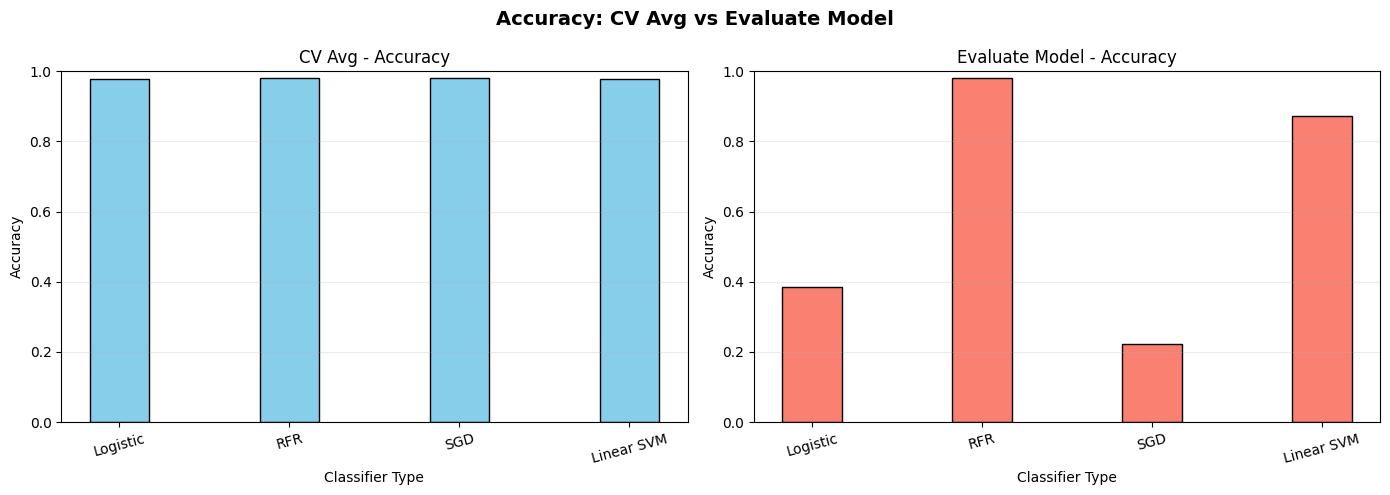

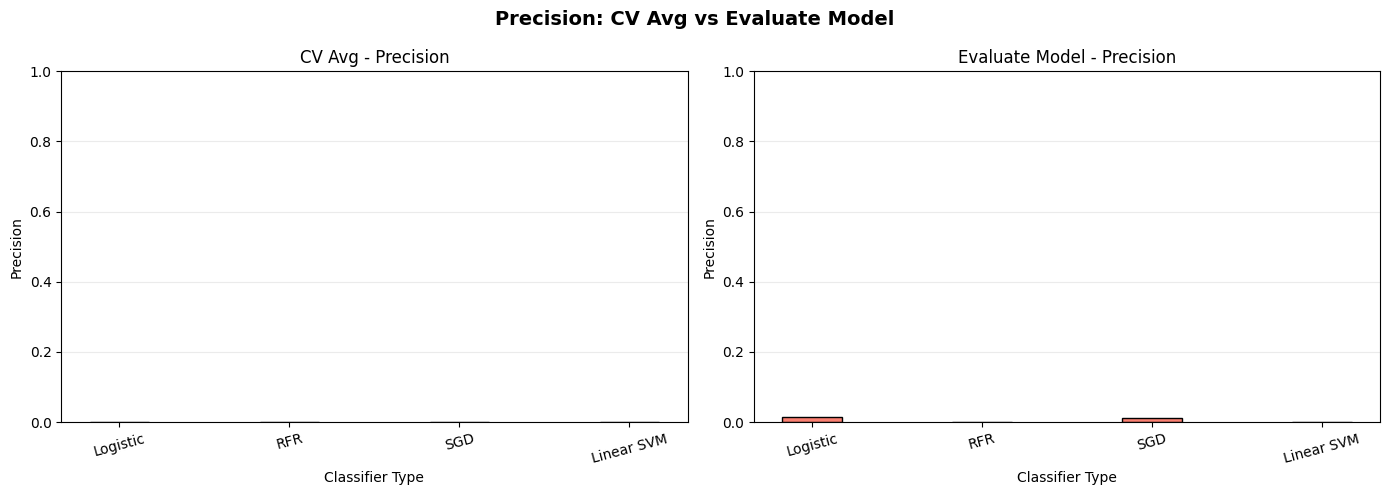

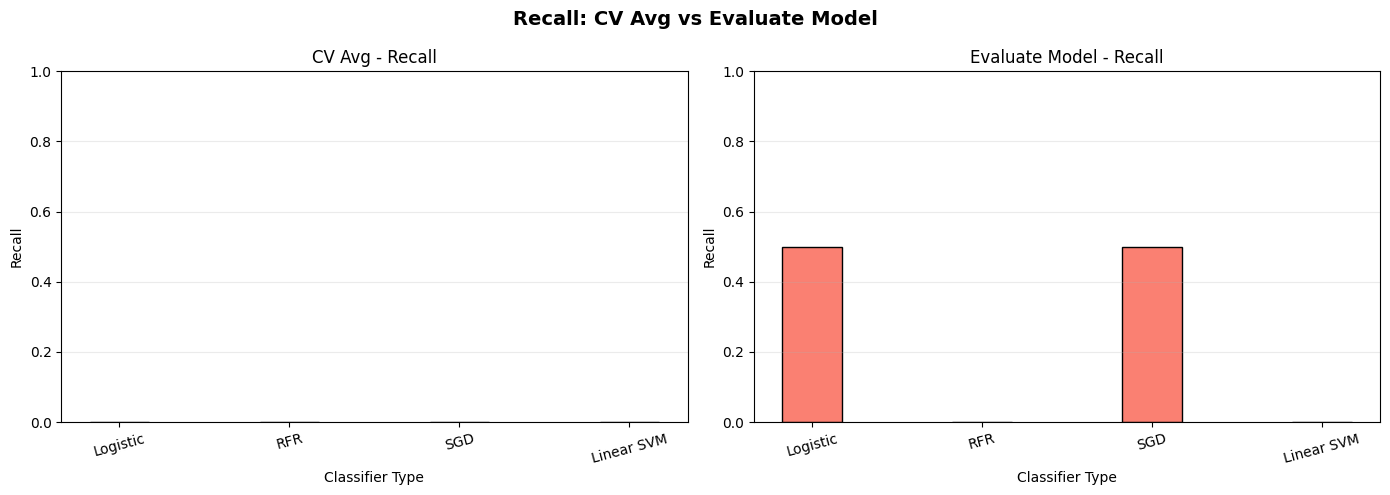

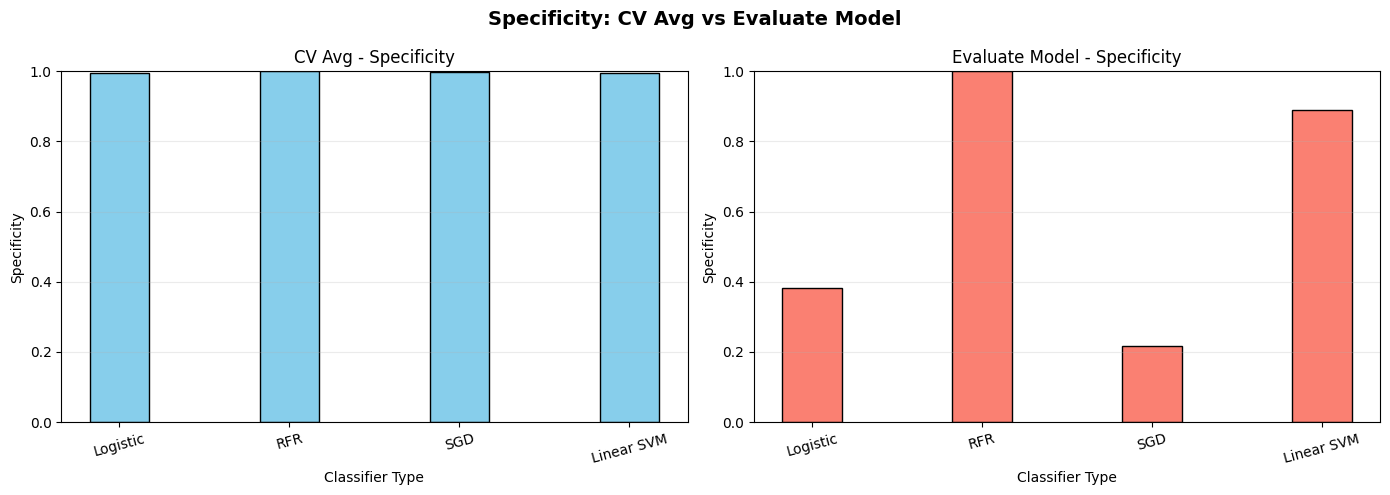

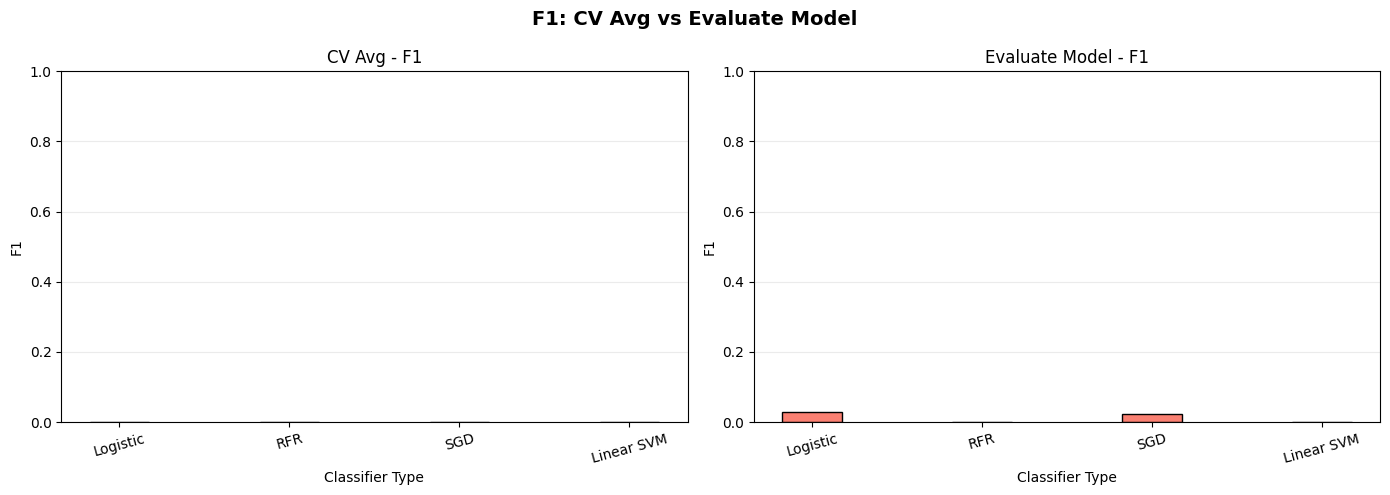

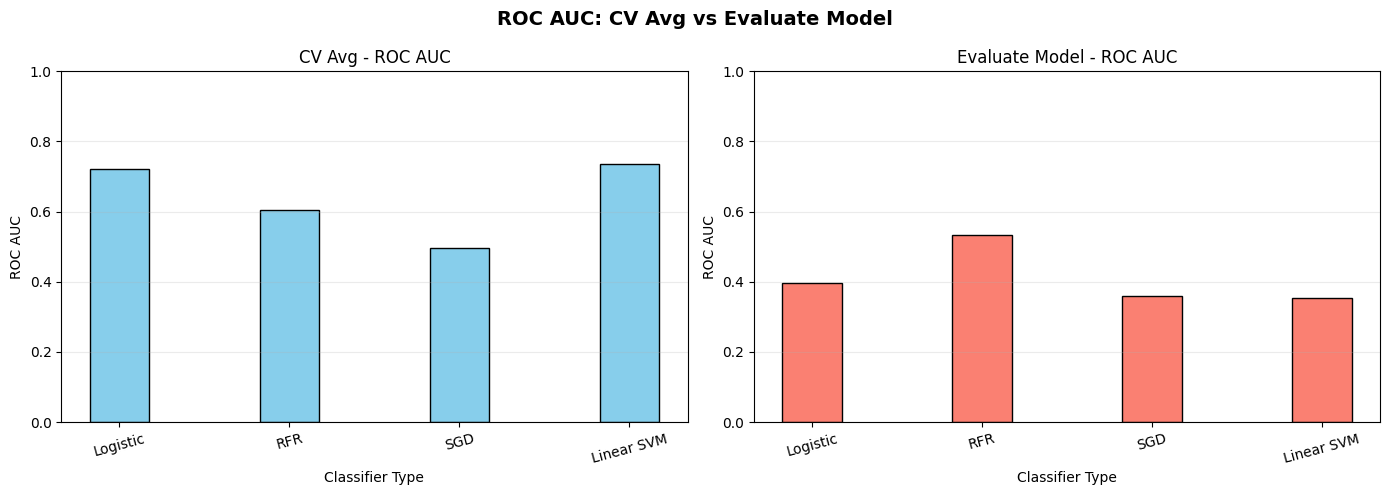

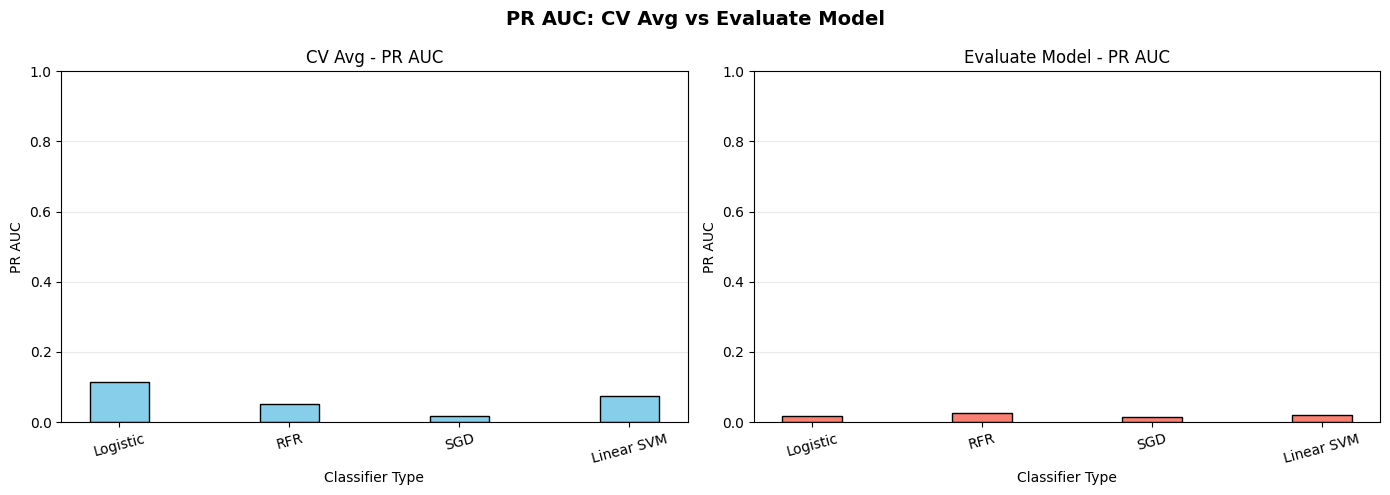

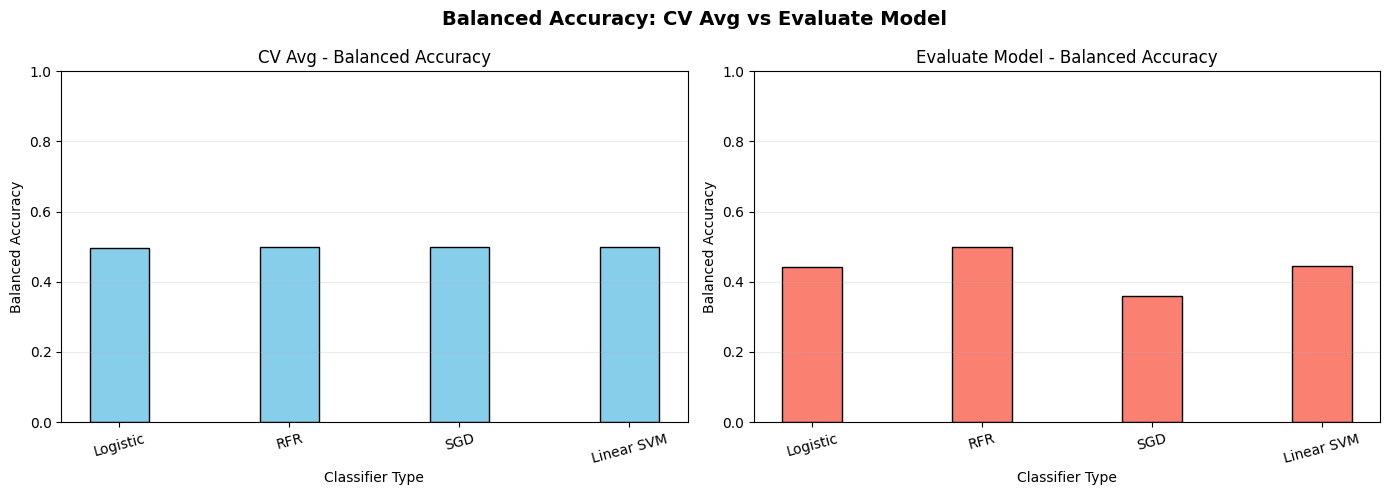

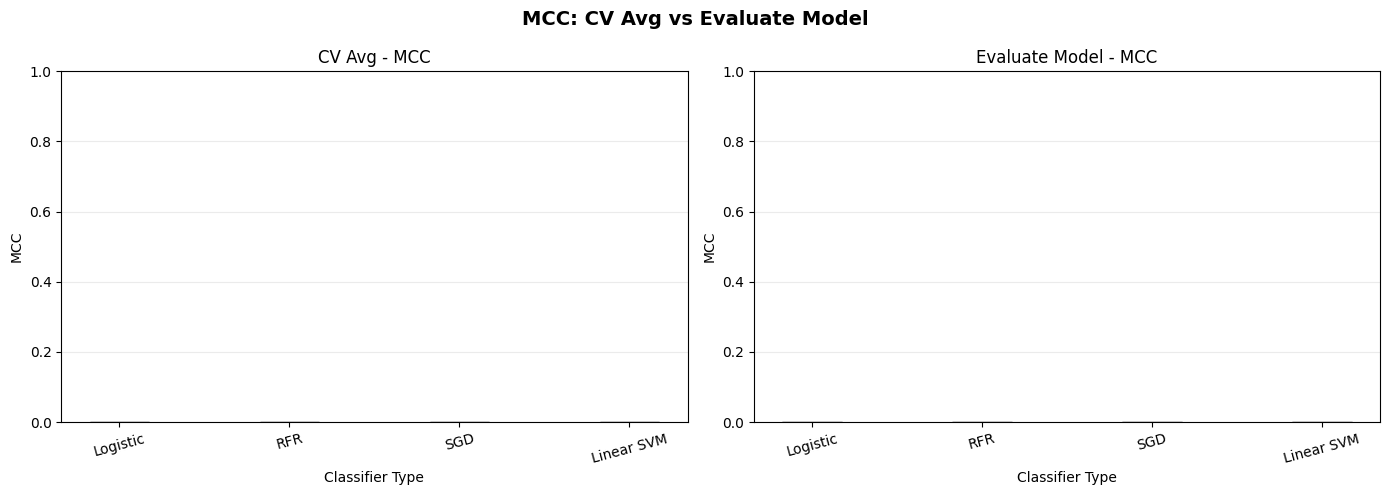

In [9]:
import matplotlib.pyplot as plt
import numpy as np

# Define classifiers to display
classifiers = ['Logistic Regression', 'Random Forest', 'SGDClassifier', 'Linear SVM']
categories = ['Logistic', 'RFR', 'SGD', 'Linear SVM']
metric_names = [
    'Accuracy',
    'Precision',
    'Recall',
    'Specificity',
    'F1',
    'ROC AUC',
    'PR AUC',
    'Balanced Accuracy',
    'MCC',
]

def get_first_dict(var_names):
    for var_name in var_names:
        value = globals().get(var_name)
        if isinstance(value, dict):
            return value
    return None

def cv_metric_value(cv_dict, model_name, metric):
    model_result = cv_dict.get(model_name)
    if model_result is None:
        return np.nan
    # Each model entry is a fold-level DataFrame; use mean across folds.
    if hasattr(model_result, 'columns') and metric in model_result.columns:
        return model_result[metric].mean()
    return np.nan

def eval_metric_value(eval_dict, model_name, metric):
    model_result = eval_dict.get(model_name, {})
    return model_result.get(metric, np.nan)

# Use CV-fold results and overall test-set evaluate-model results
cvavg = get_first_dict(['cv_resultsiv'])
overalleval = get_first_dict(['evaluate_modelsiv'])

if cvavg is None or overalleval is None:
    raise ValueError('Missing dictionaries. Expected cv_resultsiv and evaluate_modelsiv.')

for metric in metric_names:
    cvvalues = [cv_metric_value(cvavg, clf, metric) for clf in classifiers]
    overallvalues = [eval_metric_value(overalleval, clf, metric) for clf in classifiers]

    x = np.arange(len(categories))
    width = 0.35

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Panel 1: CV average across folds
    axes[0].bar(x, cvvalues, width, color='skyblue', edgecolor='black')
    axes[0].set_title(f'CV Avg - {metric}')
    axes[0].set_xlabel('Classifier Type')
    axes[0].set_ylabel(metric)
    axes[0].set_xticks(x)
    axes[0].set_xticklabels(categories, rotation=15)
    axes[0].grid(axis='y', alpha=0.25)
    axes[0].set_ylim([0, 1])

    # Panel 2: evaluate_model metrics on held-out test set
    axes[1].bar(x, overallvalues, width, color='salmon', edgecolor='black')
    axes[1].set_title(f'Evaluate Model - {metric}')
    axes[1].set_xlabel('Classifier Type')
    axes[1].set_ylabel(metric)
    axes[1].set_xticks(x)
    axes[1].set_xticklabels(categories, rotation=15)
    axes[1].grid(axis='y', alpha=0.25)
    axes[1].set_ylim([0, 1])

    fig.suptitle(f'{metric}: CV Avg vs Evaluate Model', fontsize=14, fontweight='bold')
    fig.tight_layout()
    plt.show()

In [17]:
gene_vals = [x for x in range(100, 1100, 100)]
frm = {}
emm = {}
for n_genes in range(100, 1100, 100):
    from sklearn.model_selection import train_test_split

    X_train_valiv, X_testiv, y_train_valiv, y_testiv = train_test_split(
        X,
        yiv,
        stratify=yiv,
        test_size=0.2,
        random_state=42
    )
    
    hvg_names, X_train_valiv = select_hvgs_bulk(
        X_train_valiv,
        n_top_genes=n_genes
    )
    X_testiv = X_testiv[hvg_names]

    from sklearn.svm import LinearSVC

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    model_factories = {
        "Logistic Regression": lambda: make_pipeline(
            StandardScaler(),
            LogisticRegression(max_iter=5000, class_weight="balanced")
        ),
        "SGDClassifier": lambda: make_pipeline(
            StandardScaler(),
            SGDClassifier(
                loss="log_loss",
                penalty="elasticnet",
                alpha=0.0001,
                l1_ratio=0.15,
                max_iter=1000,
                random_state=42,
            )
        ),
        "Linear SVM": lambda: make_pipeline(
            StandardScaler(),
            LinearSVC(
                class_weight="balanced",
                random_state=42,
                max_iter=10000,
            )
        ),
    }

    cv_resultsiv = {}
    trained_modelsiv = {}
    evaluate_modelsiv = {}

    for name, factory in model_factories.items():
        fold_resultsiv, best_model = cross_validate_model(factory, X_train_valiv, y_train_valiv, cv)
        cv_resultsiv[name] = fold_resultsiv
        # trained_modelsiv[name] = factory().fit(X_train_valiv, y_train_valiv)
        evaluate_modelsiv[name] = evaluate_model(best_model, X_testiv, y_testiv)
        # print(f"=== {name} ===")
        # print(
        #     fold_resultsiv[
        #         [
        #             "Recall",
        #         ]
        #     ]
        # )
        # print("Mean metrics:")
        # print(fold_resultsiv["Recall"].mean(numeric_only=True))
        # print()

        # print(evaluate_modelsiv[name]["Recall"])
        if name not in frm:
            frm[name] = []
        if name not in emm:
            emm[name] = []
        frm[name].append(fold_resultsiv["Recall"].mean(numeric_only=True))
        emm[name].append(evaluate_modelsiv[name]["Recall"])

/lustre/nvwulf/home/ronsharma/.conda/envs/py310/lib/python3.10/site-packages/sklearn/utils/validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/lustre/nvwulf/home/ronsharma/.conda/envs/py310/lib/python3.10/site-packages/sklearn/utils/validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/lustre/nvwulf/home/ronsharma/.conda/envs/py310/lib/python3.10/site-packages/sklearn/utils/validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/lustre/nvwulf/home/ronsharma/.conda/envs/py310/lib/python3.10/site-packages/sklearn/utils/validatio

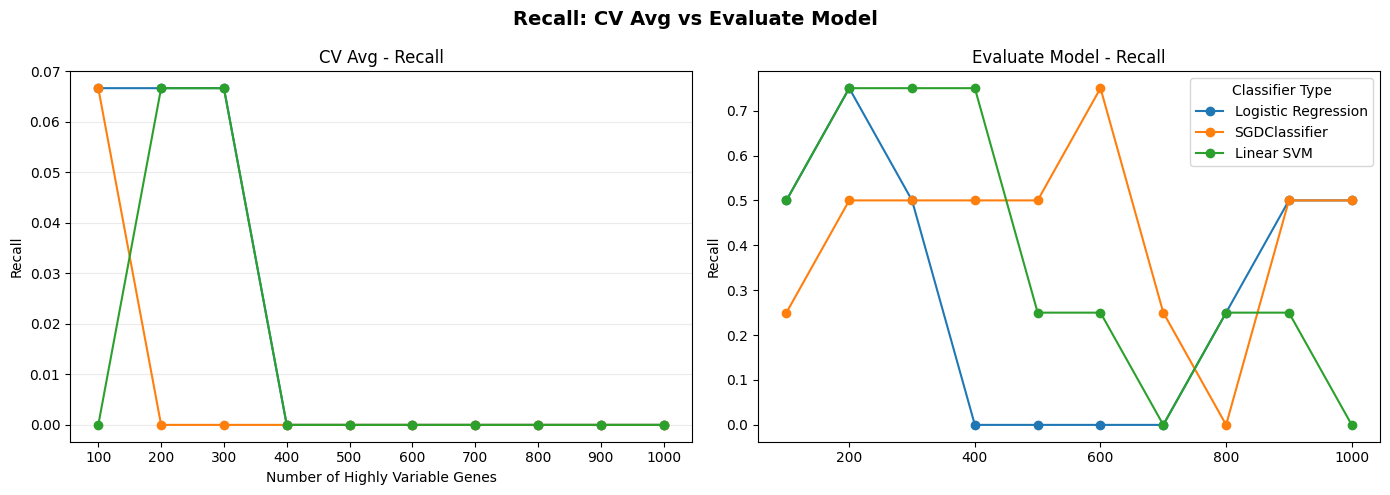

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
models = list(frm.keys())
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for model in models:
    frmvals = frm[model]
    emmvals = emm[model]

    # Panel 1: CV average across folds
    axes[0].plot(gene_vals, frmvals, marker='o', label=model)

    # Panel 2: evaluate_model metrics on held-out test set
    axes[1].plot(gene_vals, emmvals, marker='o', label=model)

legend_labels = [model for model in models]
axes[0].set_title('CV Avg - Recall')
axes[0].set_xlabel('Number of Highly Variable Genes')
axes[0].set_ylabel('Recall')
axes[0].grid(axis='y', alpha=0.25)
axes[1].set_ylabel('Recall')
axes[1].set_title('Evaluate Model - Recall')

plt.legend(legend_labels, loc='best', title='Classifier Type', fontsize=10)
fig.suptitle(f'Recall: CV Avg vs Evaluate Model', fontsize=14, fontweight='bold')
fig.tight_layout()
plt.show()

In [13]:
gene_vals = [x for x in range(1000, 10100, 500)]
frm = {}
emm = {}
for n_genes in range(1000, 10500, 500):
    from sklearn.model_selection import train_test_split

    X_train_valiv, X_testiv, y_train_valiv, y_testiv = train_test_split(
        X,
        yiv,
        stratify=yiv,
        test_size=0.2,
        random_state=42
    )
    
    hvg_names, X_train_valiv = select_hvgs_bulk(
        X_train_valiv,
        n_top_genes=n_genes
    )
    X_testiv = X_testiv[hvg_names]

    from sklearn.svm import LinearSVC

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    model_factories = {
        "Logistic Regression": lambda: make_pipeline(
            StandardScaler(),
            LogisticRegression(max_iter=5000, class_weight="balanced")
        ),
        "SGDClassifier": lambda: make_pipeline(
            StandardScaler(),
            SGDClassifier(
                loss="log_loss",
                penalty="elasticnet",
                alpha=0.0001,
                l1_ratio=0.15,
                max_iter=1000,
                random_state=42,
            )
        ),
        "Linear SVM": lambda: make_pipeline(
            StandardScaler(),
            LinearSVC(
                class_weight="balanced",
                random_state=42,
                max_iter=10000,
            )
        ),
    }

    cv_resultsiv = {}
    trained_modelsiv = {}
    evaluate_modelsiv = {}

    for name, factory in model_factories.items():
        fold_resultsiv, best_model = cross_validate_model(factory, X_train_valiv, y_train_valiv, cv)
        cv_resultsiv[name] = fold_resultsiv
        # trained_modelsiv[name] = factory().fit(X_train_valiv, y_train_valiv)
        evaluate_modelsiv[name] = evaluate_model(best_model, X_testiv, y_testiv)
        # print(f"=== {name} ===")
        # print(
        #     fold_resultsiv[
        #         [
        #             "Recall",
        #         ]
        #     ]
        # )
        # print("Mean metrics:")
        # print(fold_resultsiv["Recall"].mean(numeric_only=True))
        # print()

        # print(evaluate_modelsiv[name]["Recall"])
        if name not in frm:
            frm[name] = []
        if name not in emm:
            emm[name] = []
        frm[name].append(fold_resultsiv["Recall"].mean(numeric_only=True))
        emm[name].append(evaluate_modelsiv[name]["Recall"])

/lustre/nvwulf/home/ronsharma/.conda/envs/py310/lib/python3.10/site-packages/sklearn/utils/validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/lustre/nvwulf/home/ronsharma/.conda/envs/py310/lib/python3.10/site-packages/sklearn/utils/validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/lustre/nvwulf/home/ronsharma/.conda/envs/py310/lib/python3.10/site-packages/sklearn/utils/validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/lustre/nvwulf/home/ronsharma/.conda/envs/py310/lib/python3.10/site-packages/sklearn/utils/validatio

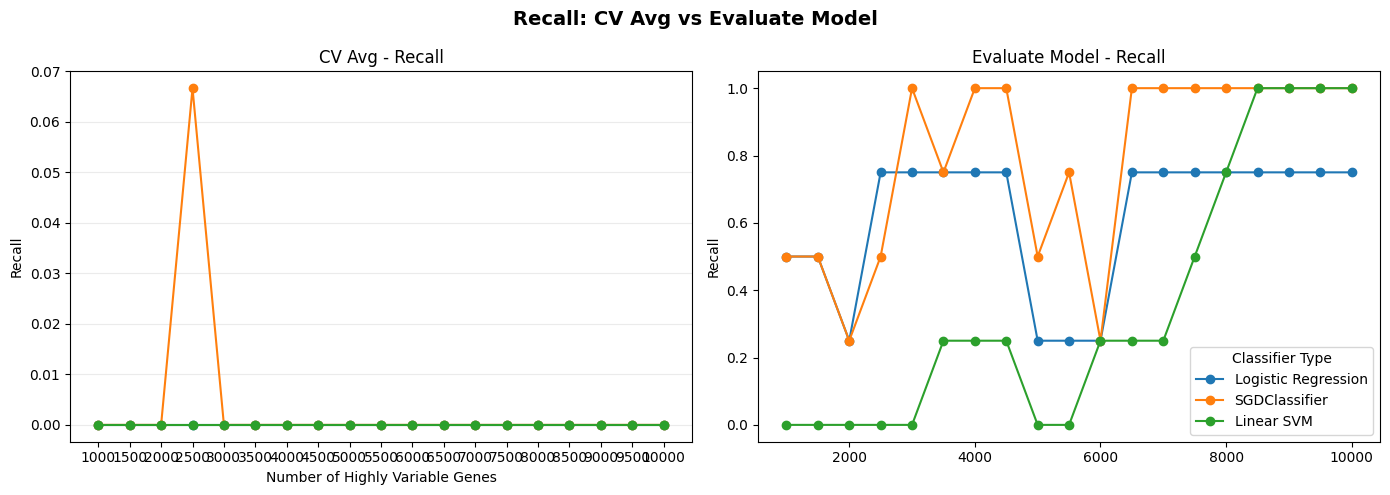

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
models = list(frm.keys())
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for model in models:
    frmvals = frm[model]
    emmvals = emm[model]

    # Panel 1: CV average across folds
    axes[0].plot(gene_vals, frmvals, marker='o', label=model)

    # Panel 2: evaluate_model metrics on held-out test set
    axes[1].plot(gene_vals, emmvals, marker='o', label=model)

legend_labels = [model for model in models]
axes[0].set_title('CV Avg - Recall')
axes[0].set_xlabel('Number of Highly Variable Genes')
axes[0].set_ylabel('Recall')
axes[0].grid(axis='y', alpha=0.25)
axes[1].set_ylabel('Recall')
axes[1].set_title('Evaluate Model - Recall')

plt.legend(legend_labels, loc='best', title='Classifier Type', fontsize=10)
fig.suptitle(f'Recall: CV Avg vs Evaluate Model', fontsize=14, fontweight='bold')
fig.tight_layout()
plt.show()